# Voice Noise Analysis 3.0

这一份 notebook 对应当前升级版实验流程。

它不再生成新的 clean voice 或 hiss noise，而是直接读取 `Codes/generated_audio` 里面 2.1 版本的正常音频。实验目标是把原来的 low-pass baseline 扩展到一个 `Wiener-style frequency-domain mask`，并直观看到：

- noisy voice 的时频特征
- low-pass baseline 的处理效果
- frequency mask 是怎么工作的
- Wiener-style mask result 和 baseline 的差别

这份 notebook 适合用来检查效果、试听结果，并挑选后续放进 PPT 的图。

## 1. 导入库与路径设置

这一节只负责读取现有音频和准备画图环境。

In [18]:
from pathlib import Path
import os
import json

os.environ.setdefault('NUMBA_CACHE_DIR', '/tmp/numba_cache')
os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')

import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from scipy import signal
from IPython.display import Audio, display

root = Path(r'/Users/xiejz959/Xiejz/College/Signal System & Probability/project/SSP_CP')

import librosa

audio_dir = Path(r'/Users/xiejz959/Xiejz/College/Signal System & Probability/project/SSP_CP/Codes/generated_audio')
voice_dir = Path(r'/Users/xiejz959/Xiejz/College/Signal System & Probability/project/SSP_CP/demo/Voices')
figure_dir = Path(r'/Users/xiejz959/Xiejz/College/Signal System & Probability/project/SSP_CP/demo/Figures')
output_dir = Path(r'/Users/xiejz959/Xiejz/College/Signal System & Probability/project/SSP_CP/Codes/improved_method_outputs')

N_PER_SEG = 1024
NO_OVERLAP = 768
DEMO_WINDOW_SEC = 4.0
FS_TARGET = 16_000

audio_dir, voice_dir, figure_dir, output_dir


(PosixPath('/Users/xiejz959/Xiejz/College/Signal System & Probability/project/SSP_CP/Codes/generated_audio'),
 PosixPath('/Users/xiejz959/Xiejz/College/Signal System & Probability/project/SSP_CP/demo/Voices'),
 PosixPath('/Users/xiejz959/Xiejz/College/Signal System & Probability/project/SSP_CP/demo/Figures'),
 PosixPath('/Users/xiejz959/Xiejz/College/Signal System & Probability/project/SSP_CP/Codes/improved_method_outputs'))

## 2. 读取 2.1 版本音频

这里读取的是队员版本 `2.1` 的音频文件，也就是 `voice_noise_analysis_2.1.ipynb` 中使用的那一批正常音频：

- `clean_voice_2.1.mp3`
- `hiss_noise_2.1.mp3`
- `noisy_voice_2.1.mp3`
- `filtered_voice_low_2.1.mp3`

其中 `filtered_voice_low_2.1.mp3` 是当前用于 baseline 对比的 low-pass 结果。

In [19]:
def read_mono(path):
    x, fs = librosa.load(path, sr=FS_TARGET, mono=True)
    return x.astype(float), fs


def align(*signals):
    n = min(len(x) for x in signals)
    return [x[:n] for x in signals]

clean, fs_clean = read_mono(audio_dir / 'clean_voice_2.1.mp3')
noise, fs_noise = read_mono(audio_dir / 'hiss_noise_2.1.mp3')
noisy, fs_noisy = read_mono(audio_dir / 'noisy_voice_2.1.mp3')
lowpass, fs_lowpass = read_mono(audio_dir / 'filtered_voice_low_2.1.mp3')

assert len({fs_clean, fs_noise, fs_noisy, fs_lowpass}) == 1
fs = fs_clean
clean, noise, noisy, lowpass = align(clean, noise, noisy, lowpass)

for name, x in [('clean', clean), ('noise', noise), ('noisy', noisy), ('lowpass', lowpass)]:
    print(f'{name}: fs={fs}, duration={len(x)/fs:.2f}s, samples={len(x)}')


clean: fs=16000, duration=30.00s, samples=480000
noise: fs=16000, duration=30.00s, samples=480000
noisy: fs=16000, duration=30.00s, samples=480000
lowpass: fs=16000, duration=30.00s, samples=480000


## 3. 先听现有音频

这一节先听原始素材和 low-pass baseline，建立直观感受。

In [21]:
for name, x in [
    ('Clean Voice', clean),
    ('Hiss Noise', noise),
    ('Noisy Voice', noisy),
    ('Low-pass Baseline', lowpass),
]:
    print(name)
    display(Audio(x, rate=fs))


Clean Voice


Hiss Noise


Noisy Voice


Low-pass Baseline


## 4. Waveform 总览

waveform 适合观察整体时域形状。这里重点看 noisy voice 是否更粗糙，以及 baseline 是否更平滑。

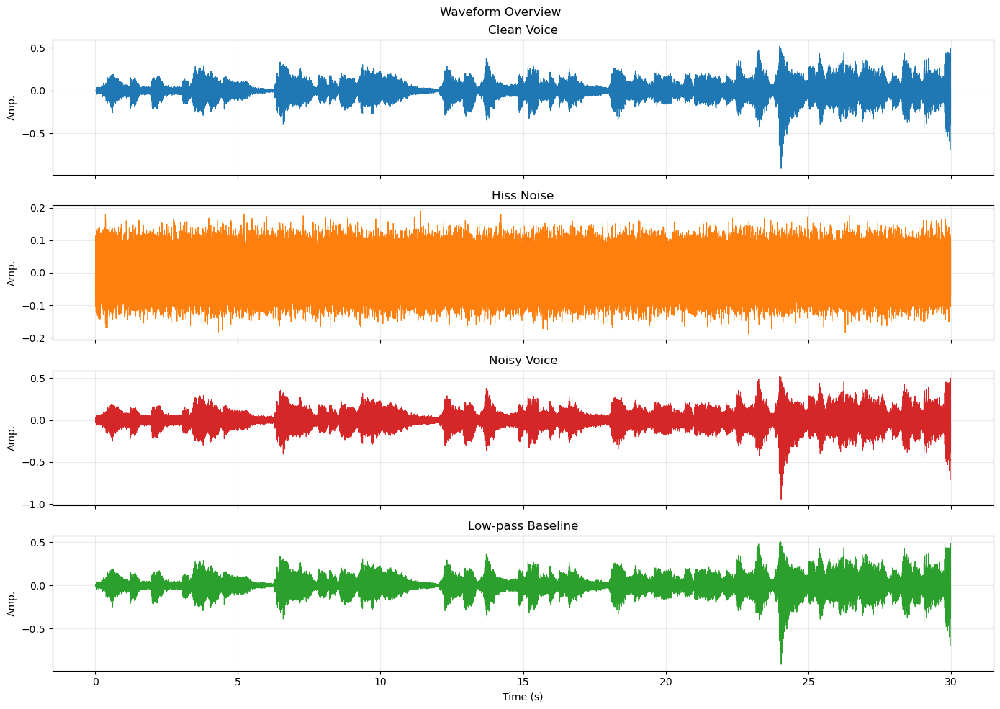

In [22]:
colors = {
    'Clean Voice': 'tab:blue',
    'Hiss Noise': 'tab:orange',
    'Noisy Voice': 'tab:red',
    'Low-pass Baseline': 'tab:green',
    'Wiener-style Mask Result': 'tab:cyan',
}

signals_basic = [
    ('Clean Voice', clean),
    ('Hiss Noise', noise),
    ('Noisy Voice', noisy),
    ('Low-pass Baseline', lowpass),
]

fig, axes = plt.subplots(len(signals_basic), 1, figsize=(14, 10), sharex=True)
for ax, (name, x) in zip(axes, signals_basic):
    t = np.arange(len(x)) / fs
    ax.plot(t, x, color=colors[name], linewidth=0.7)
    ax.set_title(name)
    ax.set_ylabel('Amp.')
    ax.grid(alpha=0.25)
axes[-1].set_xlabel('Time (s)')
plt.suptitle('Waveform Overview')
plt.tight_layout()
plt.show()


## 5. FFT magnitude spectrum

FFT 图用来观察整体频率能量分布。这里可以验证 noisy voice 的高频能量是否被抬高，以及 low-pass 是否压低了高频部分。

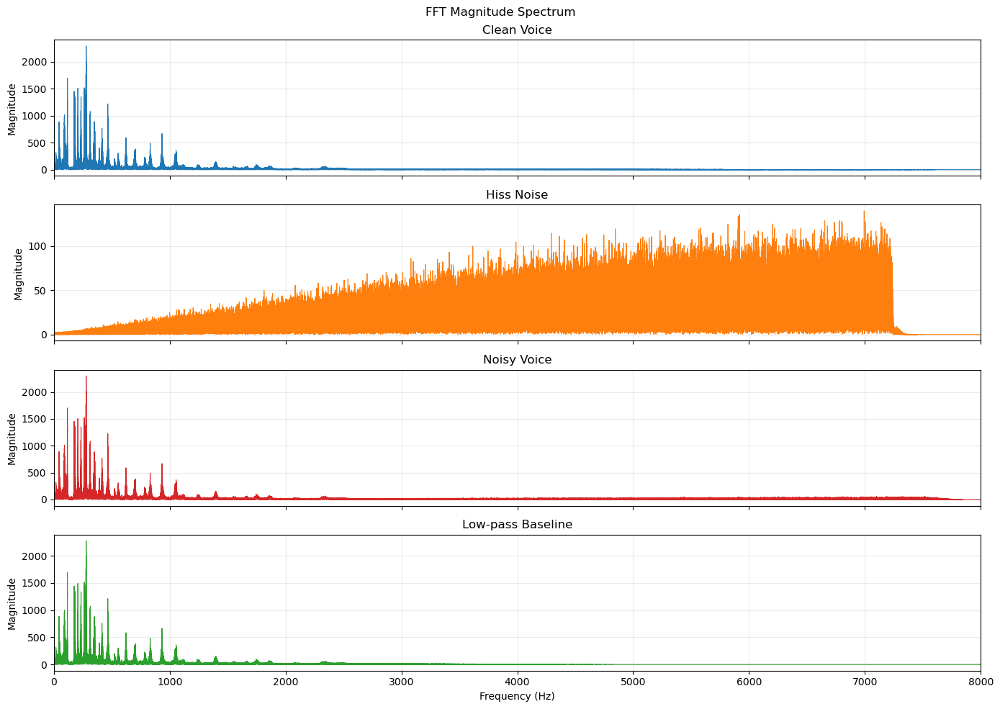

In [23]:
def magnitude_spectrum(x, fs):
    freqs = np.fft.rfftfreq(len(x), 1 / fs)
    mag = np.abs(np.fft.rfft(x))
    return freqs, mag

fig, axes = plt.subplots(len(signals_basic), 1, figsize=(14, 10), sharex=True)
for ax, (name, x) in zip(axes, signals_basic):
    freqs, mag = magnitude_spectrum(x, fs)
    ax.plot(freqs, mag, color=colors[name], linewidth=0.8)
    ax.set_title(name)
    ax.set_ylabel('Magnitude')
    ax.grid(alpha=0.25)
axes[-1].set_xlabel('Frequency (Hz)')
axes[-1].set_xlim(0, fs / 2)
plt.suptitle('FFT Magnitude Spectrum')
plt.tight_layout()
plt.show()


## 6. Spectrogram: clean / noisy / low-pass

spectrogram 可以看作时间-频率能量图。横轴是时间，纵轴是频率，颜色越亮表示能量越强。

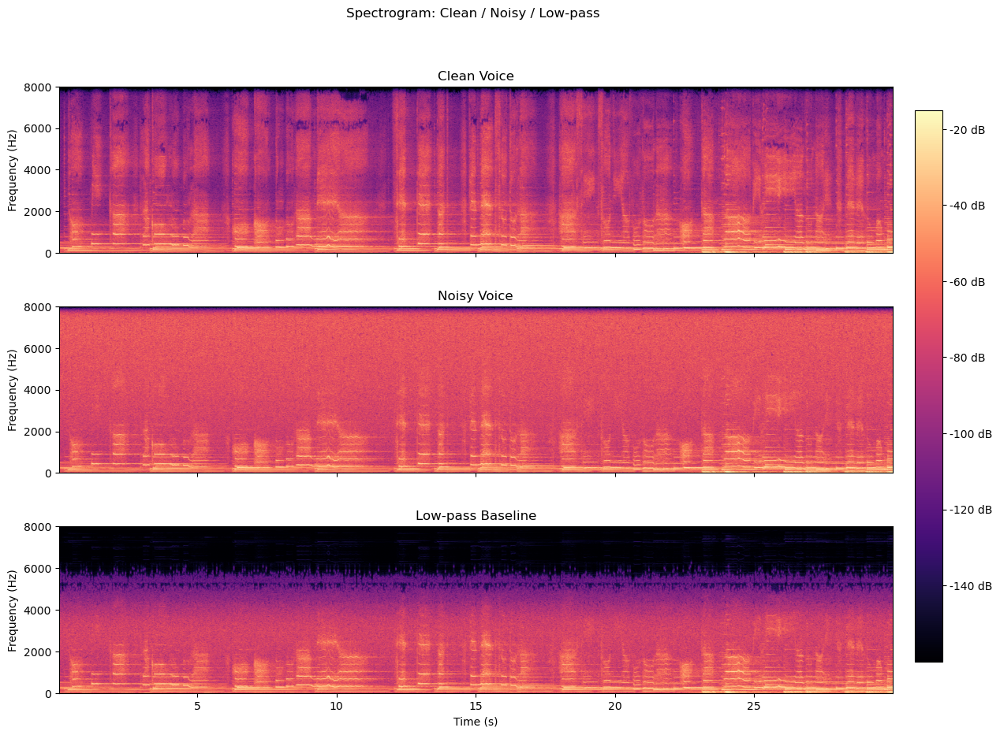

In [24]:
def spectrogram_db(x, fs):
    freqs, times, spec = signal.spectrogram(
        x,
        fs=fs,
        window='hann',
        nperseg=N_PER_SEG,
        noverlap=NO_OVERLAP,
        scaling='spectrum',
        mode='magnitude',
    )
    return freqs, times, 20 * np.log10(spec + 1e-8)

spec_names = [('Clean Voice', clean), ('Noisy Voice', noisy), ('Low-pass Baseline', lowpass)]
fig, axes = plt.subplots(len(spec_names), 1, figsize=(14, 10), sharex=True)
img = None
for ax, (name, x) in zip(axes, spec_names):
    freqs, times, spec_db = spectrogram_db(x, fs)
    img = ax.pcolormesh(times, freqs, spec_db, shading='gouraud', cmap='magma')
    ax.set_title(name)
    ax.set_ylabel('Frequency (Hz)')
    ax.set_ylim(0, fs / 2)
axes[-1].set_xlabel('Time (s)')
fig.subplots_adjust(right=0.88, hspace=0.32)
cax = fig.add_axes([0.90, 0.15, 0.025, 0.70])
fig.colorbar(img, cax=cax, format='%+2.0f dB')
plt.suptitle('Spectrogram: Clean / Noisy / Low-pass')
plt.show()


## 7. Improved method: Wiener-style frequency mask

这里开始进入升级方法。

核心思想是：low-pass 是固定 mask，而 Wiener-style mask 会根据语音和噪声的相对能量，决定每个频率或时频区域保留多少。

In [25]:
MASK_FLOOR = 0.12
NOISE_OVER_ESTIMATE = 0.4
MASK_SMOOTHING_BINS = 1


def peak_normalize(x, peak=0.92):
    m = np.max(np.abs(x))
    return x.copy() if m == 0 else x * (peak / m)


def rms_match(reference, estimate):
    ref_rms = np.sqrt(np.mean(reference**2) + 1e-12)
    est_rms = np.sqrt(np.mean(estimate**2) + 1e-12)
    return estimate * (ref_rms / est_rms)


def moving_average_frequency(mask, bins):
    if bins <= 1:
        return mask
    kernel = np.ones(bins) / bins
    smoothed = np.empty_like(mask)
    for frame in range(mask.shape[1]):
        smoothed[:, frame] = np.convolve(mask[:, frame], kernel, mode='same')
    return smoothed

freqs, times, noisy_stft = signal.stft(
    noisy,
    fs=fs,
    window='hann',
    nperseg=N_PER_SEG,
    noverlap=NO_OVERLAP,
    boundary='zeros',
    padded=True,
)
_, _, noise_stft = signal.stft(
    noise,
    fs=fs,
    window='hann',
    nperseg=N_PER_SEG,
    noverlap=NO_OVERLAP,
    boundary='zeros',
    padded=True,
)

noisy_power = np.abs(noisy_stft) ** 2
noise_power = np.mean(np.abs(noise_stft) ** 2, axis=1, keepdims=True)
estimated_speech_power = np.maximum(noisy_power - NOISE_OVER_ESTIMATE * noise_power, 0.0)

mask = estimated_speech_power / (estimated_speech_power + noise_power + 1e-12)
mask = moving_average_frequency(mask, MASK_SMOOTHING_BINS)
mask = np.clip(mask, MASK_FLOOR, 1.0)

enhanced_stft = mask * noisy_stft
_, wiener_masked = signal.istft(
    enhanced_stft,
    fs=fs,
    window='hann',
    nperseg=N_PER_SEG,
    noverlap=NO_OVERLAP,
    input_onesided=True,
    boundary=True,
)
wiener_masked = wiener_masked[:len(noisy)]
wiener_masked = rms_match(noisy, wiener_masked)
wiener_masked = peak_normalize(wiener_masked)

sf.write(voice_dir / 'wiener_masked_voice_3.1.wav', wiener_masked, fs)
print('Saved:', voice_dir / 'wiener_masked_voice_3.1.wav')


Saved: /Users/xiejz959/Xiejz/College/Signal System & Probability/project/SSP_CP/demo/Voices/wiener_masked_voice_3.1.wav


## 8. 试听 improved method

这里把 noisy、low-pass baseline 和 Wiener-style mask result 放在一起听。

In [27]:
for name, x in [
    ('Noisy Voice', noisy),
    ('Low-pass Baseline', lowpass),
    ('Wiener-style Mask Result', wiener_masked),
]:
    print(name)
    display(Audio(x, rate=fs))


Noisy Voice


Low-pass Baseline


Wiener-style Mask Result


## 9. Mask 图

这张图是升级方法最重要的可视化之一。颜色越亮，表示该时间-频率区域保留得越多；颜色越暗，表示压制越多。

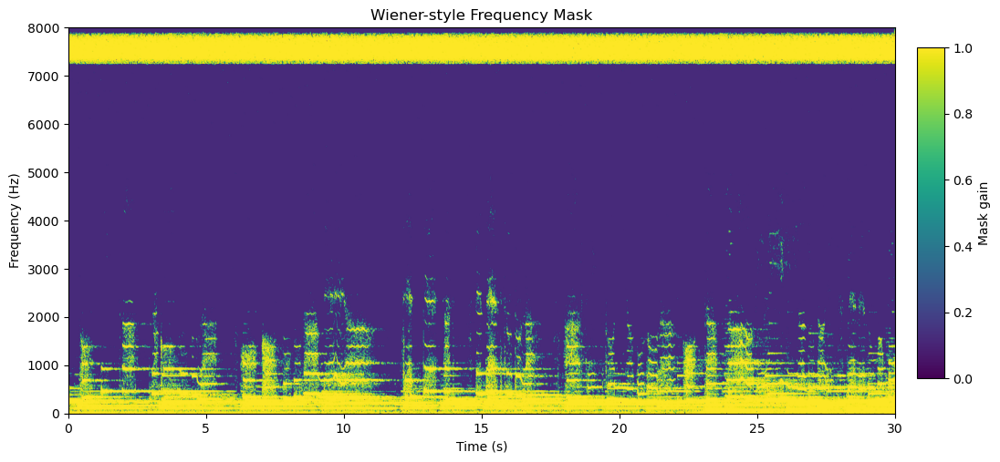

In [28]:
fig, ax = plt.subplots(figsize=(12, 5.5))
img = ax.pcolormesh(times, freqs, mask, shading='gouraud', cmap='viridis', vmin=0, vmax=1)
ax.set_title('Wiener-style Frequency Mask')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Frequency (Hz)')
ax.set_ylim(0, fs / 2)
fig.subplots_adjust(right=0.88)
cax = fig.add_axes([0.90, 0.18, 0.025, 0.66])
fig.colorbar(img, cax=cax, label='Mask gain')
plt.show()


## 10. Noisy -> Mask -> Enhanced

这一组三联图最适合放到 PPT 里，因为它直接展示 improved method 的处理逻辑。

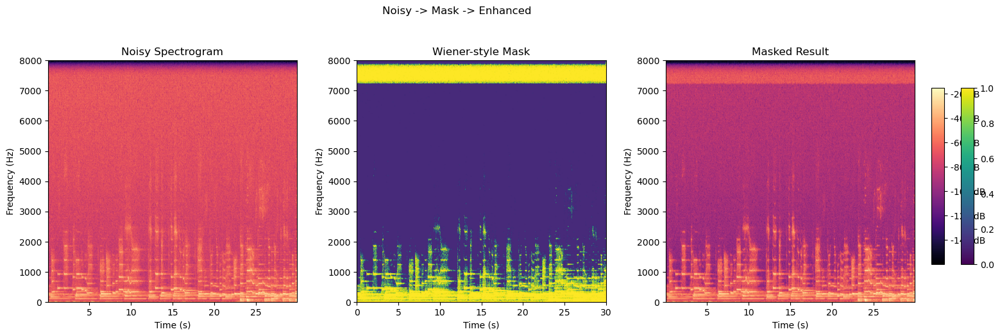

In [29]:
def draw_spec_on_axis(ax, x, fs, title):
    freqs_s, times_s, spec_db = spectrogram_db(x, fs)
    img = ax.pcolormesh(times_s, freqs_s, spec_db, shading='gouraud', cmap='magma')
    ax.set_title(title)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Frequency (Hz)')
    ax.set_ylim(0, fs / 2)
    return img

fig, axes = plt.subplots(1, 3, figsize=(17, 5.3))
img0 = draw_spec_on_axis(axes[0], noisy, fs, 'Noisy Spectrogram')
img1 = axes[1].pcolormesh(times, freqs, mask, shading='gouraud', cmap='viridis', vmin=0, vmax=1)
axes[1].set_title('Wiener-style Mask')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_ylim(0, fs / 2)
img2 = draw_spec_on_axis(axes[2], wiener_masked, fs, 'Masked Result')
fig.suptitle('Noisy -> Mask -> Enhanced')
fig.subplots_adjust(right=0.92, wspace=0.24, top=0.82)
cax_spec = fig.add_axes([0.935, 0.22, 0.012, 0.52])
fig.colorbar(img2, cax=cax_spec, format='%+2.0f dB')
cax_mask = fig.add_axes([0.962, 0.22, 0.012, 0.52])
fig.colorbar(img1, cax=cax_mask)
plt.show()


## 11. Method comparison

这里比较 noisy、low-pass baseline 和 Wiener-style mask result。注意：mask 方法不一定在所有指标上都超过 low-pass，它的价值主要是展示更灵活、更细粒度的频域处理思想。

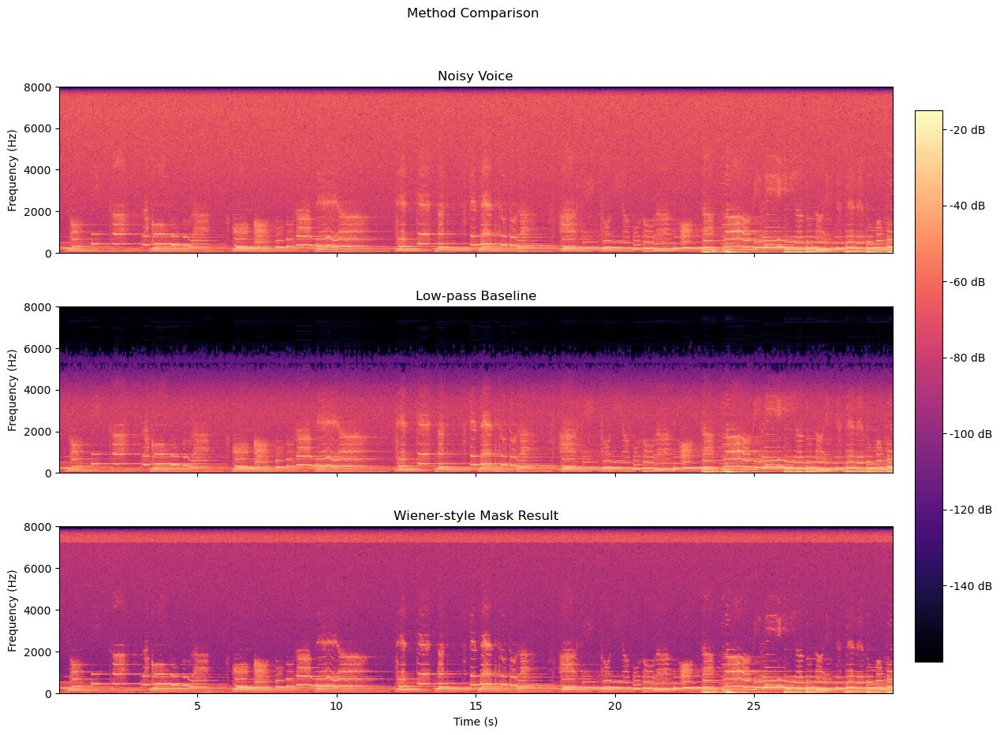

In [30]:
comparison = [
    ('Noisy Voice', noisy),
    ('Low-pass Baseline', lowpass),
    ('Wiener-style Mask Result', wiener_masked),
]
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
img = None
for ax, (name, x) in zip(axes, comparison):
    freqs_s, times_s, spec_db = spectrogram_db(x, fs)
    img = ax.pcolormesh(times_s, freqs_s, spec_db, shading='gouraud', cmap='magma')
    ax.set_title(name)
    ax.set_ylabel('Frequency (Hz)')
    ax.set_ylim(0, fs / 2)
axes[-1].set_xlabel('Time (s)')
fig.subplots_adjust(right=0.88, hspace=0.32)
cax = fig.add_axes([0.90, 0.15, 0.025, 0.70])
fig.colorbar(img, cax=cax, format='%+2.0f dB')
plt.suptitle('Method Comparison')
plt.show()


## 12. Demo 窗口 waveform 对比

这里只看前 4 秒，方便选择后续 PPT 或现场 demo 的片段。

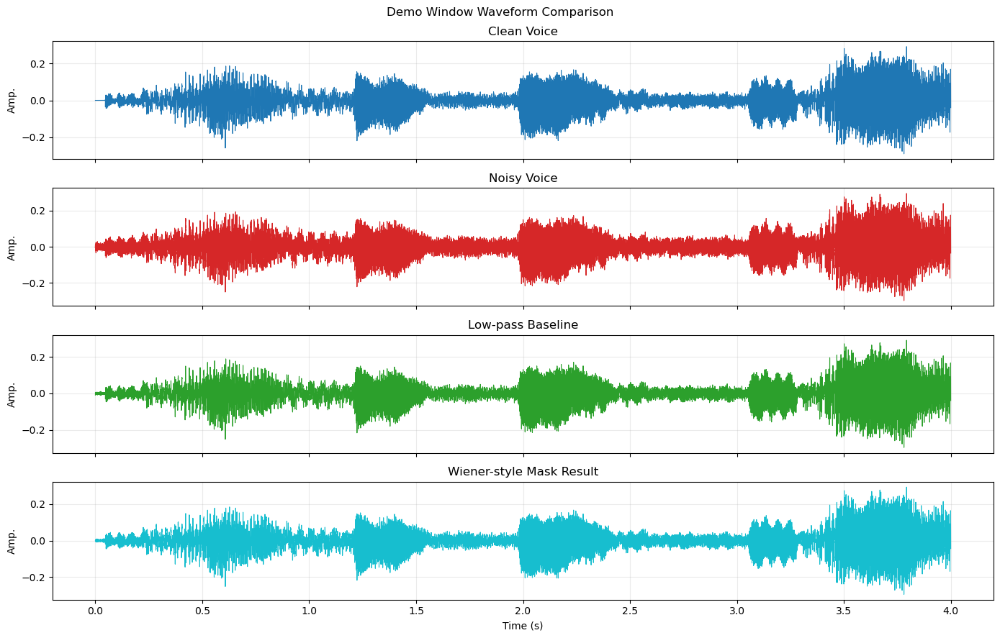

In [31]:
wave_signals = [
    ('Clean Voice', clean, 'tab:blue'),
    ('Noisy Voice', noisy, 'tab:red'),
    ('Low-pass Baseline', lowpass, 'tab:green'),
    ('Wiener-style Mask Result', wiener_masked, 'tab:cyan'),
]
n = min(int(DEMO_WINDOW_SEC * fs), *(len(x) for _, x, _ in wave_signals))
t = np.arange(n) / fs

fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
for ax, (name, x, color) in zip(axes, wave_signals):
    ax.plot(t, x[:n], color=color, linewidth=0.8)
    ax.set_title(name)
    ax.set_ylabel('Amp.')
    ax.grid(alpha=0.25)
axes[-1].set_xlabel('Time (s)')
plt.suptitle('Demo Window Waveform Comparison')
plt.tight_layout()
plt.show()


## 13. 简单指标对比

这里用 SNR 和高频能量比例做一个辅助比较。它们不是最终评价语音质量的唯一标准，但可以帮助说明方法的变化。

In [32]:
def snr_db(reference, estimate):
    error = estimate - reference
    return float(10 * np.log10(np.sum(reference**2) / (np.sum(error**2) + 1e-12)))


def high_frequency_ratio(reference_input, estimate, fs, start_hz=3500):
    input_fft = np.abs(np.fft.rfft(reference_input))
    estimate_fft = np.abs(np.fft.rfft(estimate))
    freqs_h = np.fft.rfftfreq(len(reference_input), 1 / fs)
    idx = freqs_h >= start_hz
    return float(np.mean(estimate_fft[idx]) / (np.mean(input_fft[idx]) + 1e-12))

metrics = {
    'Noisy Voice': {
        'SNR vs clean (dB)': snr_db(clean, noisy),
        'High-frequency ratio vs noisy': 1.0,
    },
    'Low-pass Baseline': {
        'SNR vs clean (dB)': snr_db(clean, lowpass),
        'SNR improvement (dB)': snr_db(clean, lowpass) - snr_db(clean, noisy),
        'High-frequency ratio vs noisy': high_frequency_ratio(noisy, lowpass, fs),
    },
    'Wiener-style Mask Result': {
        'SNR vs clean (dB)': snr_db(clean, wiener_masked),
        'SNR improvement (dB)': snr_db(clean, wiener_masked) - snr_db(clean, noisy),
        'High-frequency ratio vs noisy': high_frequency_ratio(noisy, wiener_masked, fs),
    },
}

for method, values in metrics.items():
    print(method)
    for k, v in values.items():
        print(f'  {k}: {v:.4f}')


Noisy Voice
  SNR vs clean (dB): 17.4948
  High-frequency ratio vs noisy: 1.0000
Low-pass Baseline
  SNR vs clean (dB): 23.9739
  SNR improvement (dB): 6.4791
  High-frequency ratio vs noisy: 0.0475
Wiener-style Mask Result
  SNR vs clean (dB): 21.9868
  SNR improvement (dB): 4.4920
  High-frequency ratio vs noisy: 0.2349


## 14. 保存 3.1 实验输出

这一节会把 improved method 的音频、mask 数据、图和指标保存到项目对应文件夹。

In [33]:
figure_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)

sf.write(voice_dir / 'wiener_masked_voice_3.1.wav', wiener_masked, fs)
np.savez_compressed(
    output_dir / 'wiener_mask_data_3.1.npz',
    freqs=freqs,
    times=times,
    mask=mask,
    enhanced=wiener_masked,
    fs=np.array([fs]),
)
with open(output_dir / 'notebook_metrics_3.0.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

# Save selected figures from notebook flow.
fig, ax = plt.subplots(figsize=(12, 5.5))
img = ax.pcolormesh(times, freqs, mask, shading='gouraud', cmap='viridis', vmin=0, vmax=1)
ax.set_title('Wiener-style Frequency Mask')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Frequency (Hz)')
ax.set_ylim(0, fs / 2)
fig.subplots_adjust(right=0.88)
cax = fig.add_axes([0.90, 0.18, 0.025, 0.66])
fig.colorbar(img, cax=cax, label='Mask gain')
fig.savefig(figure_dir / 'wiener_mask_notebook_3.0.png', dpi=180, bbox_inches='tight')
plt.close(fig)

print('Saved audio:', voice_dir / 'wiener_masked_voice_3.1.wav')
print('Saved mask data:', output_dir / 'wiener_mask_data_3.1.npz')
print('Saved notebook metrics:', output_dir / 'notebook_metrics_3.0.json')
print('Saved figure:', figure_dir / 'wiener_mask_notebook_3.0.png')


Saved audio: /Users/xiejz959/Xiejz/College/Signal System & Probability/project/SSP_CP/demo/Voices/wiener_masked_voice_3.1.wav
Saved mask data: /Users/xiejz959/Xiejz/College/Signal System & Probability/project/SSP_CP/Codes/improved_method_outputs/wiener_mask_data_3.1.npz
Saved notebook metrics: /Users/xiejz959/Xiejz/College/Signal System & Probability/project/SSP_CP/Codes/improved_method_outputs/notebook_metrics_3.0.json
Saved figure: /Users/xiejz959/Xiejz/College/Signal System & Probability/project/SSP_CP/demo/Figures/wiener_mask_notebook_3.0.png


## 15. 当前解释建议

这版 improved method 最适合这样讲：

- low-pass 是一个固定的 frequency mask，简单但比较粗
- Wiener-style mask 是更灵活的频域遮蔽方法
- mask 图能直观看到哪些时间-频率区域被保留，哪些被压制
- 这不一定意味着所有指标都超过 low-pass，但它能更好地展示从基础滤波到更细粒度频域处理的升级思路
